In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
files = list(Path("../data").rglob("*.xls*"))
print(f'Number of files: {len(files)}')

for file in files:
    print(file)

Number of files: 18
../data/2025/23MARCH25-1MAY25.xls
../data/2025/AUG 2025.xls
../data/2025/DEC 2025.xls
../data/2025/JAN 2025.xls
../data/2025/JULY 2025.xls
../data/2025/JuNE 2025.xls
../data/2025/MAY 2025.xls
../data/2025/NOV2025.xls
../data/2025/OCT 2025.xls
../data/2025/SEP 2025.xls
../data/2026/APR20-MAY42026.xls
../data/2026/August 2026.xls
../data/2026/FEB 2026.xls
../data/2026/JAN 2026.xls
../data/2026/JULY2026.xls
../data/2026/june 2026.xls
../data/2026/MARCH-APR 20.xls
../data/2026/MAY 2026.xls


In [4]:
df = pd.read_csv(files[0], sep='\t')
df.columns

Index(['Date(dd/mm/yy)', 'Time(HH:MM)', 'W Direction(Deg)', 'Temp(Deg C)',
       'R Humidity(%)', 'Solar(CCM)', 'B Pressure(mmHg)', 'Spd(Km/hr)',
       'Rain(mm)', 'Unnamed: 9'],
      dtype='str')

In [5]:
temperature_data = []

for file in files:
    df = pd.read_csv(file, sep="\t")

    df = df[
        ["Date(dd/mm/yy)", "Time(HH:MM)", "Temp(Deg C)"]
    ]

    temperature_data.append(df)

temperature_data = pd.concat(
    temperature_data,
    ignore_index=True
)

print(temperature_data.head())
print(temperature_data.info())

  Date(dd/mm/yy) Time(HH:MM)    Temp(Deg C)
0       24/03/25       13:57             Or
1       24/03/25       14:00           37.5
2       24/03/25       14:27             Or
3       24/03/25       14:46             Or
4       24/03/25       15:23             Or
<class 'pandas.DataFrame'>
RangeIndex: 12692 entries, 0 to 12691
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Date(dd/mm/yy)  12692 non-null  str  
 1   Time(HH:MM)     12692 non-null  str  
 2   Temp(Deg C)     12692 non-null  str  
dtypes: str(3)
memory usage: 297.6 KB
None


In [6]:
print("Total observations:", len(temperature_data))

print("\nMissing values:")
print(temperature_data.isnull().sum())

print("\nUnique non-numeric values:")
print(
    temperature_data[
        pd.to_numeric(
            temperature_data["Temp(Deg C)"],
            errors="coerce"
        ).isna()
    ]["Temp(Deg C)"].value_counts()
)

Total observations: 12692

Missing values:
Date(dd/mm/yy)    0
Time(HH:MM)       0
Temp(Deg C)       0
dtype: int64

Unique non-numeric values:
Temp(Deg C)
           Or       254
-Transfer Error-     77
Name: count, dtype: int64


In [7]:
temperature_data["Temp(Deg C)"] = pd.to_numeric(
    temperature_data["Temp(Deg C)"],
    errors="coerce"
)

temperature_clean = temperature_data.dropna(
    subset=["Temp(Deg C)"]
).copy()

temperature_clean["Datetime"] = pd.to_datetime(
    temperature_clean["Date(dd/mm/yy)"].astype(str) + " " +
    temperature_clean["Time(HH:MM)"].astype(str),
    dayfirst=True,
    format="mixed",
    errors="coerce"
)

temperature_clean = temperature_clean.dropna(
    subset=["Datetime"]
)

temperature_clean = temperature_clean.sort_values("Datetime")

print("\nObservations after cleaning:", len(temperature_clean))

print("\nTemperature statistics:")
print(temperature_clean["Temp(Deg C)"].describe())

print("\nMinimum temperature:",
      temperature_clean["Temp(Deg C)"].min())

print("Maximum temperature:",
      temperature_clean["Temp(Deg C)"].max())

print("\nEarliest reading:", temperature_clean["Datetime"].min())
print("Latest reading:", temperature_clean["Datetime"].max())


Observations after cleaning: 12361

Temperature statistics:
count    12361.000000
mean        27.927676
std          6.216970
min         11.000000
25%         25.000000
50%         27.500000
75%         31.300000
max         53.500000
Name: Temp(Deg C), dtype: float64

Minimum temperature: 11.0
Maximum temperature: 53.5

Earliest reading: 0110-10-11 08:00:00
Latest reading: 2026-09-07 12:00:00


In [8]:
print(
    temperature_clean[
        temperature_clean["Datetime"].dt.year < 2020
    ].to_string(index=False)
)

print("Temperatures above 40°C:")

print(
    temperature_clean[
        temperature_clean["Temp(Deg C)"] > 40
    ][["Date(dd/mm/yy)", "Time(HH:MM)", "Temp(Deg C)"]]
    .to_string(index=False)
)

print("\nTemperatures below 15°C:")

print(
    temperature_clean[
        temperature_clean["Temp(Deg C)"] < 15
    ][["Date(dd/mm/yy)", "Time(HH:MM)", "Temp(Deg C)"]]
    .to_string(index=False)
)

print(
    temperature_clean.nlargest(15, "Temp(Deg C)")[
        ["Date(dd/mm/yy)", "Time(HH:MM)", "Temp(Deg C)"]
    ].to_string(index=False)
)

Date(dd/mm/yy) Time(HH:MM)  Temp(Deg C)           Datetime
          8:00       110.0         53.5 110-10-11 08:00:00
Temperatures above 40°C:
Date(dd/mm/yy) Time(HH:MM)  Temp(Deg C)
          8:00       110.0         53.5
      26/03/25       15:00         40.4
      27/03/25       13:00         40.4
      27/03/25       14:00         41.2
      27/03/25       15:00         41.2
      27/03/25       16:00         41.2
      27/03/25       17:00         40.2
      28/03/25       14:00         41.4
      28/03/25       15:00         42.0
      28/03/25       16:00         40.3
      28/03/25       17:00         40.6
      29/03/25       15:00         40.5
      30/03/25       15:00         40.4
      30/03/25       17:00         40.4
      05/04/25       15:00         40.2
      06/04/25       13:00         40.1
      06/04/25       14:00         41.5
      06/04/25       15:00         41.0
      06/04/25       16:00         41.2
      06/04/25       17:00         41.5
      06/04/25   

In [9]:
temperature_clean = temperature_clean[
    temperature_clean["Datetime"].dt.year >= 2020
].copy()

print("Observations after removing malformed record:",
      len(temperature_clean))

print("\nUpdated statistics:")
print(temperature_clean["Temp(Deg C)"].describe())

Observations after removing malformed record: 12360

Updated statistics:
count    12360.000000
mean        27.925607
std          6.212964
min         11.000000
25%         25.000000
50%         27.500000
75%         31.300000
max         46.600000
Name: Temp(Deg C), dtype: float64


In [10]:
temperature_clean = temperature_clean.sort_values("Datetime")

duplicate_check_temp = (
    temperature_clean.groupby("Datetime")["Temp(Deg C)"]
    .agg(["count", "nunique"])
)

duplicate_check_temp = duplicate_check_temp[
    duplicate_check_temp["count"] > 1
]

print("Duplicate timestamps:", len(duplicate_check_temp))

print(
    "Timestamps with conflicting readings:",
    (duplicate_check_temp["nunique"] > 1).sum()
)

Duplicate timestamps: 89
Timestamps with conflicting readings: 0


In [11]:
temperature_clean = temperature_clean.drop_duplicates(
    subset=["Datetime", "Temp(Deg C)"]
).copy()

print("Observations after deduplication:", len(temperature_clean))

print(
    "Remaining duplicate timestamps:",
    temperature_clean["Datetime"].duplicated().sum()
)

temperature_clean["Month"] = (
    temperature_clean["Datetime"].dt.to_period("M")
)

monthly_temperature = (
    temperature_clean.groupby("Month")
    .agg(
        Average_Temp=("Temp(Deg C)", "mean"),
        Maximum_Temp=("Temp(Deg C)", "max"),
        Minimum_Temp=("Temp(Deg C)", "min"),
        Observations=("Temp(Deg C)", "count")
    )
    .reset_index()
)

print(monthly_temperature.to_string(index=False))

Observations after deduplication: 12271
Remaining duplicate timestamps: 0
  Month  Average_Temp  Maximum_Temp  Minimum_Temp  Observations
2024-12     22.511445          33.2          11.1           699
2025-01     20.316364          30.2          13.2            55
2025-03     32.253143          42.0          22.1           175
2025-04     33.365120          44.5          22.0           711
2025-05     31.979973          42.3          22.0           739
2025-06     31.313007          44.1          23.1           715
2025-07     27.474024          36.3          22.2           743
2025-08     28.208356          36.4          23.2           742
2025-09     27.936681          36.6          23.2           717
2025-10     27.476996          35.1          21.3           739
2025-11     22.635063          33.3          14.1           713
2025-12     19.651421          30.5          12.1           739
2026-01     21.338160          31.5          11.0           739
2026-02     24.962969         

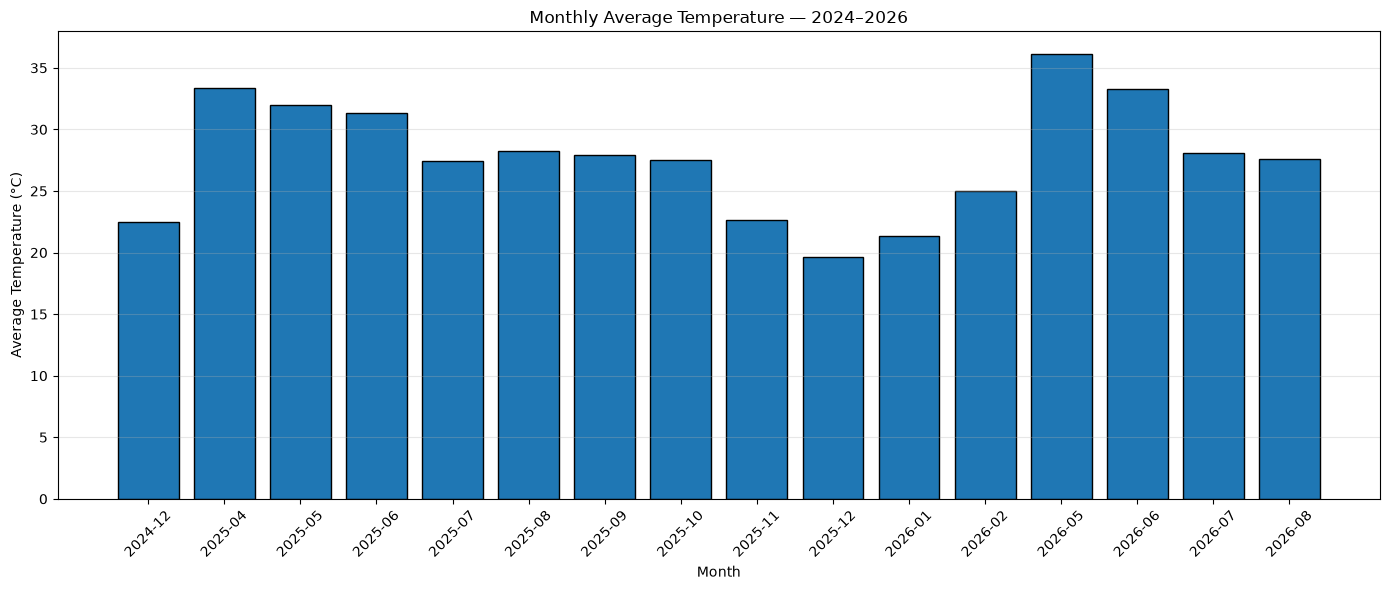

In [12]:
temperature_reliable = monthly_temperature[
    monthly_temperature["Observations"] >= 600
].copy()

temperature_reliable["Month"] = (
    temperature_reliable["Month"].astype(str)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    temperature_reliable["Month"],
    temperature_reliable["Average_Temp"],
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.title("Monthly Average Temperature — 2024–2026")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

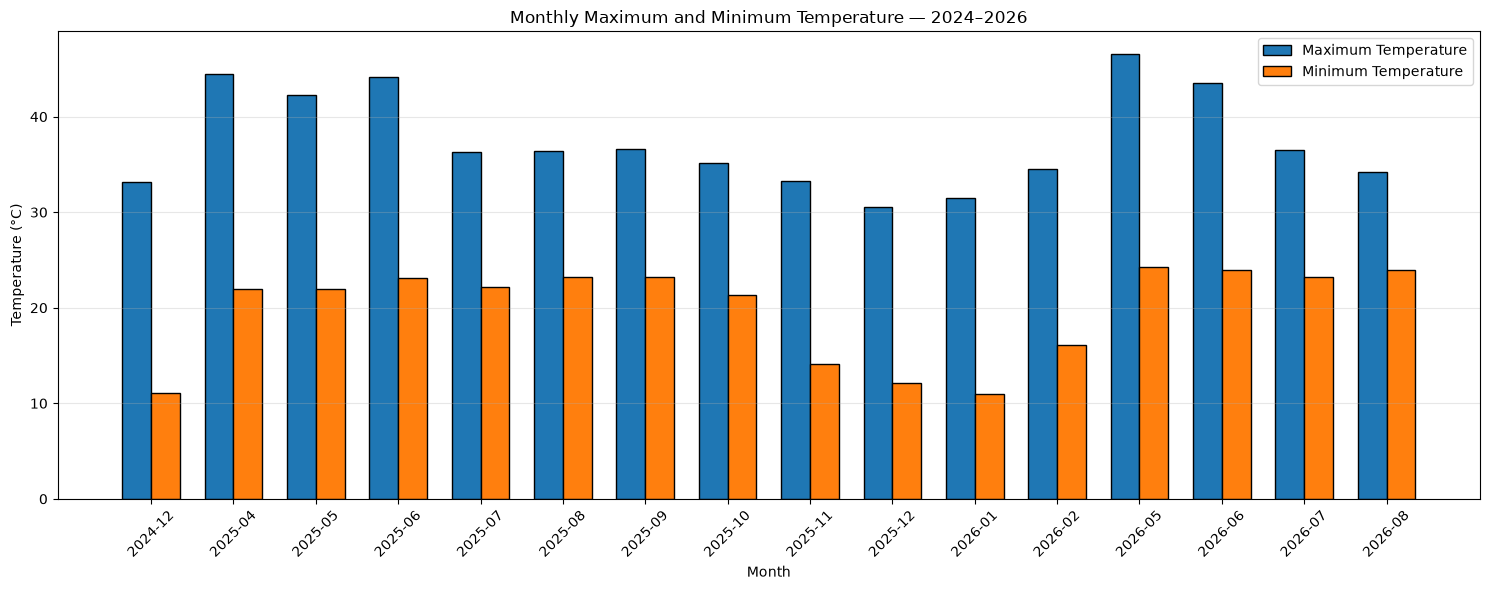

In [13]:
import numpy as np
import matplotlib.pyplot as plt

months = temperature_reliable["Month"]
x = np.arange(len(months))
width = 0.35

plt.figure(figsize=(15, 6))

plt.bar(
    x - width/2,
    temperature_reliable["Maximum_Temp"],
    width,
    label="Maximum Temperature",
    edgecolor="black"
)

plt.bar(
    x + width/2,
    temperature_reliable["Minimum_Temp"],
    width,
    label="Minimum Temperature",
    edgecolor="black"
)

plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.title("Monthly Maximum and Minimum Temperature — 2024–2026")

plt.xticks(x, months, rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()